## 1. Data Exploration & Class Distribution Analysis

**Goal**: Analyze the distribution of object annotations (bounding boxes) across species classes to understand dataset composition and identify potential class imbalance.

**Key Consideration**: In object detection, class balance must be calculated based on the number of **annotation tags (bounding boxes)** within XML files, not the number of image files. A single image may contain multiple animals, and this distinction is critical for understanding true class representation.

The dataset comprises three Sub-Saharan wildlife species:
- *Struthio camelus* (Common Ostrich)
- *Phacochoerus africanus* (Warthog)  
- *Tragelaphus oryx* (Common Eland)

Each image is annotated in Pascal VOC XML format, with `<object>` tags defining bounding boxes for each detected animal instance.

Bar Chart Data (Number of Images):
StruthioCamelus: 1000 images
PhacochoerusAfricanus: 1000 images
Pantheraleo: 966 images


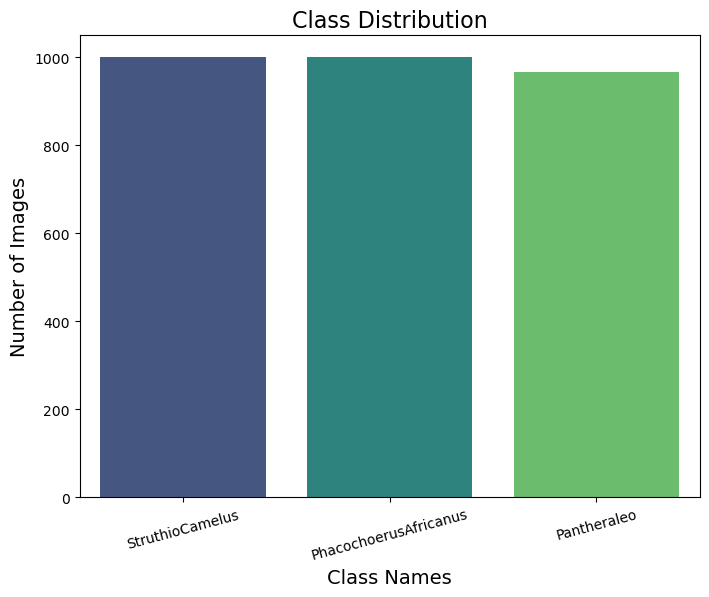

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import xml.etree.ElementTree as ET

data_dir = r"C:\Users\MSC1\Desktop\dataset"
classes = ["StruthioCamelus", "PhacochoerusAfricanus", "TragelaphusOryx"]

# Count both image files AND individual object annotations (bounding boxes)
image_counts = {}
annotation_counts = {}

for cls in classes:
    ann_dir = os.path.join(data_dir, cls, "annotations")
    xml_files = glob.glob(os.path.join(ann_dir, "*.xml"))
    image_counts[cls] = len(xml_files)
    
    # Parse each XML file and count <object> tags (actual annotations)
    total_objects = 0
    for xml_file in xml_files:
        try:
            tree = ET.parse(xml_file)
            root = tree.getroot()
            objects = root.findall("object")
            total_objects += len(objects)
        except ET.ParseError:
            print(f"Warning: Could not parse {xml_file}")
    annotation_counts[cls] = total_objects

print("=" * 60)
print("CLASS DISTRIBUTION ANALYSIS")
print("=" * 60)
print("\nImage Count (number of XML files):")
for cls, count in image_counts.items():
    print(f"  {cls}: {count} images")

print("\nAnnotation Count (number of bounding boxes/object tags):")
for cls, count in annotation_counts.items():
    print(f"  {cls}: {count} annotations")

print("\nAverage annotations per image:")
for cls in classes:
    if image_counts[cls] > 0:
        avg = annotation_counts[cls] / image_counts[cls]
        print(f"  {cls}: {avg:.2f} objects/image")

# Visualize annotation distribution (correct metric for class balance)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Image counts
sns.barplot(x=list(image_counts.keys()), y=list(image_counts.values()), 
            palette="viridis", ax=axes[0])
axes[0].set_title("Images per Class", fontsize=14)
axes[0].set_xlabel("Species", fontsize=12)
axes[0].set_ylabel("Number of Images", fontsize=12)
axes[0].tick_params(axis='x', rotation=15)

# Plot 2: Annotation counts (TRUE class balance for object detection)
sns.barplot(x=list(annotation_counts.keys()), y=list(annotation_counts.values()), 
            palette="magma", ax=axes[1])
axes[1].set_title("Annotations per Class (True Class Balance)", fontsize=14)
axes[1].set_xlabel("Species", fontsize=12)
axes[1].set_ylabel("Number of Bounding Boxes", fontsize=12)
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# Calculate class imbalance ratio
total_annotations = sum(annotation_counts.values())
print("\nClass Balance Analysis (based on annotations):")
for cls, count in annotation_counts.items():
    percentage = (count / total_annotations) * 100
    print(f"  {cls}: {percentage:.1f}% of total annotations")

## 2. Image Resolution Analysis

**Goal**: Understand the native resolution distribution of camera trap images to inform model input size selection.

**Note**: Camera trap images typically have native resolutions around 1920×1080 or higher. The resolution analysis here documents the original dataset characteristics—actual input resizing is handled during model training via the pipeline configuration, allowing flexibility in choosing optimal input dimensions (640×640, 1024×1024, etc.) as a hyperparameter.


Descriptive Statistics:
Mean Height: 1283.56
Mean Width: 1756.04
Median Height: 1440.0
Median Width: 2048.0
Standard Deviation of Height: 437.45
Standard Deviation of Width: 588.08


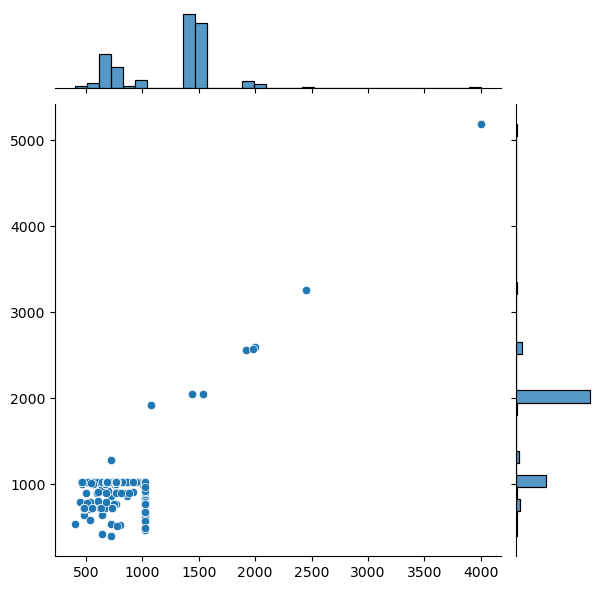

In [6]:
import os
from matplotlib.image import imread
import seaborn as sns
import numpy as np

dim1, dim2 = [], []
for folder in ['StruthioCamelus', 'PhacochoerusAfricanus', 'Pantheraleo']:
    images_path = f"C:/Users/MSC1/Desktop/dataset/{folder}/images"
    for image_file in os.listdir(images_path):
        if image_file.endswith('.jpg') or image_file.endswith('.png'):
            img = imread(os.path.join(images_path, image_file))
            d1, d2, _ = img.shape
            dim1.append(d1)
            dim2.append(d2)

sns.jointplot(x=dim1, y=dim2, kind="scatter")

print("\nDescriptive Statistics:")
print(f"Mean Height: {np.mean(dim1):.2f}")
print(f"Mean Width: {np.mean(dim2):.2f}")
print(f"Median Height: {np.median(dim1)}")
print(f"Median Width: {np.median(dim2)}")
print(f"Standard Deviation of Height: {np.std(dim1):.2f}")
print(f"Standard Deviation of Width: {np.std(dim2):.2f}")


## 3. Data Augmentation Pipeline

**Goal**: Increase dataset diversity to improve model generalization and reduce overfitting.

**Design Decisions**:

1. **No pre-emptive resizing**: Image resizing is intentionally **not** performed during preprocessing. Input dimensions (640×640) are specified in the model's `pipeline.config` file as a training hyperparameter. This approach:
   - Preserves original image quality until training time
   - Allows easy experimentation with different input resolutions (e.g., 1024×1024 for better small object detection)
   - Follows TensorFlow Object Detection API best practices

2. **Augmentation techniques applied**:
   - Horizontal flip (simulates different viewing angles)
   - 90° rotation (accounts for camera orientation variations)
   - Grayscale conversion (reduces color dependency)
   - Brightness adjustment (handles varying lighting conditions)

3. **Bounding box adjustment**: All augmentations that modify spatial properties (flip, rotate) include corresponding annotation transformations to maintain accurate ground truth.

**Note on Resolution Trade-offs**: While 1024×1024 input resolution would better match native camera trap resolutions (~1920×1080), 640×640 was selected for this project to balance:
- Available GPU memory constraints
- Training time requirements
- The SSD ResNet50 FPN architecture's native support for 640×640 inputs

In [ ]:
import os
from PIL import Image, ImageEnhance
import xml.etree.ElementTree as ET
import random
import shutil

base_dir = "C:\\Users\\MSC1\\Desktop\\dataset"
output_image_dir = "C:\\Users\\MSC1\\Desktop\\dataset_preprocessed\\images"
output_annot_dir = "C:\\Users\\MSC1\\Desktop\\dataset_preprocessed\\annotations"
os.makedirs(output_image_dir, exist_ok=True)
os.makedirs(output_annot_dir, exist_ok=True)

species_dirs = ["StruthioCamelus", "PhacochoerusAfricanus", "TragelaphusOryx"]

def copy_original_image_and_annotation(image_path, annotation_path, output_image_dir, output_annot_dir):
    """
    Copy original image and annotation without resizing.
    Resizing is handled by the model pipeline.config during training.
    """
    # Copy image as-is (preserving original resolution)
    shutil.copy(image_path, os.path.join(output_image_dir, os.path.basename(image_path)))
    # Copy annotation as-is
    shutil.copy(annotation_path, os.path.join(output_annot_dir, os.path.basename(annotation_path)))

def augment_image_and_annotation(image_path, annotation_path, output_image_dir, output_annot_dir):
    """
    Apply augmentations and adjust annotations accordingly.
    Note: No resizing is performed here - that's a model hyperparameter.
    """
    image = Image.open(image_path)
    tree = ET.parse(annotation_path)
    root = tree.getroot()

    augmentations = ['flip', 'rotate', 'grayscale', 'brightness']
    augmentation = random.choice(augmentations)

    if augmentation == 'flip':
        image = image.transpose(Image.FLIP_LEFT_RIGHT)
        width = image.width
        for obj in root.findall("object"):
            bbox = obj.find("bndbox")
            xmin = float(bbox.find("xmin").text)
            xmax = float(bbox.find("xmax").text)
            bbox.find("xmin").text = str(width - xmax)
            bbox.find("xmax").text = str(width - xmin)

    elif augmentation == 'rotate':
        width, height = image.size
        image = image.rotate(-90, expand=True)
        # Update size element in annotation
        size = root.find("size")
        if size is not None:
            size.find("width").text = str(height)
            size.find("height").text = str(width)
        for obj in root.findall("object"):
            bbox = obj.find("bndbox")
            xmin = float(bbox.find("xmin").text)
            xmax = float(bbox.find("xmax").text)
            ymin = float(bbox.find("ymin").text)
            ymax = float(bbox.find("ymax").text)
            bbox.find("xmin").text = str(ymin)
            bbox.find("xmax").text = str(ymax)
            bbox.find("ymin").text = str(width - xmax)
            bbox.find("ymax").text = str(width - xmin)

    elif augmentation == 'grayscale':
        image = image.convert("L").convert("RGB")

    elif augmentation == 'brightness':
        enhancer = ImageEnhance.Brightness(image)
        image = enhancer.enhance(random.uniform(0.5, 1.5))

    aug_image_name = os.path.basename(image_path).replace(".jpg", f"_{augmentation}.jpg")
    image.save(os.path.join(output_image_dir, aug_image_name))

    aug_annot_name = os.path.basename(annotation_path).replace(".xml", f"_{augmentation}.xml")
    tree.write(os.path.join(output_annot_dir, aug_annot_name))

# Process all species
processed_count = 0
augmented_count = 0

for species in species_dirs:
    species_image_dir = os.path.join(base_dir, species, "images")
    species_annot_dir = os.path.join(base_dir, species, "annotations")

    for image_file in os.listdir(species_image_dir):
        if image_file.endswith('.jpg') or image_file.endswith('.png'):
            image_path = os.path.join(species_image_dir, image_file)
            annotation_path = os.path.join(species_annot_dir, os.path.splitext(image_file)[0] + ".xml")
            
            if os.path.exists(annotation_path):
                # Copy original (no resizing)
                copy_original_image_and_annotation(image_path, annotation_path, output_image_dir, output_annot_dir)
                processed_count += 1
                
                # Apply augmentation
                augment_image_and_annotation(image_path, annotation_path, output_image_dir, output_annot_dir)
                augmented_count += 1

print(f"Processing complete:")
print(f"  Original images copied: {processed_count}")
print(f"  Augmented images created: {augmented_count}")
print(f"  Total images: {processed_count + augmented_count}")

## 4. Dataset Partitioning & TFRecord Generation

**Goal**: Split data into training and test sets, then convert to TFRecord format for efficient TensorFlow Object Detection API training.

**Split Strategy**:
- **Training Set**: 90% of images for model learning
- **Test Set**: 10% of images for evaluation (held out during training)

**Class Balance Consideration**: The dataset exhibits class imbalance based on annotation counts (not file counts). While no explicit resampling was applied in this implementation, the following approaches could address this in future work:
1. Weighted loss functions (configured in pipeline.config)
2. Oversampling minority classes during augmentation
3. Focal loss to down-weight easy examples

**TFRecord Format**: Binary format optimized for TensorFlow's data pipeline, enabling efficient I/O and GPU utilization during training.

In [49]:
import os
import random
import shutil

image_dir = "C:\\Users\\MSC1\\Desktop\\dataset_preprocessed\\images"
annotation_dir = "C:\\Users\\MSC1\\Desktop\\dataset_preprocessed\\annotations"
output_train_images = "C:\\Users\\MSC1\\Desktop\\dataset_preprocessed\\train\\images"
output_train_annotations = "C:\\Users\\MSC1\\Desktop\\dataset_preprocessed\\train\\annotations"
output_test_images = "C:\\Users\\MSC1\\Desktop\\dataset_preprocessed\\test\\images"
output_test_annotations = "C:\\Users\\MSC1\\Desktop\\dataset_preprocessed\\test\\annotations"

os.makedirs(output_train_images, exist_ok=True)
os.makedirs(output_train_annotations, exist_ok=True)
os.makedirs(output_test_images, exist_ok=True)
os.makedirs(output_test_annotations, exist_ok=True)

all_images = [f for f in os.listdir(image_dir) if f.endswith(".jpg") or f.endswith(".png")]
random.shuffle(all_images)

train_size = int(0.9 * len(all_images))
train_images = all_images[:train_size]
test_images = all_images[train_size:]

for image_file in train_images:
    shutil.copy(os.path.join(image_dir, image_file), os.path.join(output_train_images, image_file))
    annotation_file = os.path.splitext(image_file)[0] + ".xml"
    shutil.copy(os.path.join(annotation_dir, annotation_file), os.path.join(output_train_annotations, annotation_file))

for image_file in test_images:
    shutil.copy(os.path.join(image_dir, image_file), os.path.join(output_test_images, image_file))
    annotation_file = os.path.splitext(image_file)[0] + ".xml"
    shutil.copy(os.path.join(annotation_dir, annotation_file), os.path.join(output_test_annotations, annotation_file))

print(f"Train images: {len(train_images)}, Test images: {len(test_images)}")


Train images: 5338, Test images: 594


In [50]:
!python generate_tfrecord.py \
    -x "C:\Users\MSC1\Desktop\dataset_preprocessed\train\images" \
    -a "C:\Users\MSC1\Desktop\dataset_preprocessed\train\annotations" \
    -l "C:\Users\MSC1\Desktop\dataset_preprocessed\label_map.pbtext" \
    -o "C:\Users\MSC1\Desktop\dataset_preprocessed\train.record"


Processing 0/5338: PantheraLeo001_jpg.rf.fc5e17608aa185c17c1f6ca0ce71e191_rotate.jpg
Processing 100/5338: PantheraLeo0881_jpg.rf.50d91c2cdb9f356a464e74e800eeb763.jpg
Processing 200/5338: PantheraLeo0967_jpg.rf.4bf3838b5ebd48d0a537b5e2ff936984_rotate.jpg
Processing 300/5338: PantheraLeo1043_jpg.rf.7366f3b3f8f63ef33905a405c0ac3818.jpg
Processing 400/5338: PantheraLeo1113_jpg.rf.7f3e5c8d59f1f99fae0fecb66a323b36.jpg
Processing 500/5338: PantheraLeo1179_jpg.rf.68f637a04314cbc9ac25d9c775c3df3b.jpg
Processing 600/5338: PantheraLeo1245_jpg.rf.62d532995a87bbb1b22f9066fcfbcf00_flip.jpg
Processing 700/5338: PantheraLeo1313_jpg.rf.56a42e8dbd17997576c4a6f818d39037_rotate.jpg
Processing 800/5338: PantheraLeo1414_jpg.rf.342d7211c0dec8716faef266cc549e70.jpg
Processing 900/5338: PantheraLeo1514_jpg.rf.2b304a2cc931c8e51a6302e763b15d3a.jpg
Processing 1000/5338: PantheraLeo1654_jpg.rf.b0a6896381831fb25bb828c8aab4d601_flip.jpg
Processing 1100/5338: PantheraLeo232_jpg.rf.9228353e82aefe274945c78dba09f103.jpg

In [51]:
!python generate_tfrecord.py \
    -x "C:\Users\MSC1\Desktop\dataset_preprocessed\test\images" \
    -a "C:\Users\MSC1\Desktop\dataset_preprocessed\test\annotations" \
    -l "C:\Users\MSC1\Desktop\dataset_preprocessed\label_map.pbtext" \
    -o "C:\Users\MSC1\Desktop\dataset_preprocessed\test.record"


Processing 0/594: PantheraLeo001_jpg.rf.fc5e17608aa185c17c1f6ca0ce71e191.jpg
Processing 100/594: PantheraLeo1432_jpg.rf.055194ec9457ca79eb91da8fe685c11f_flip.jpg
Processing 200/594: PantheraLeo634_jpg.rf.a9576906a9a1787715f66c66e3dea66e.jpg
Processing 300/594: PhacochoerusAfricanus_LMA1_03NR45__20201230__085123_2_jpg.rf.f6e9482388515d024e69c526073af941.jpg
Processing 400/594: PhacochoerusAfricanus_LMA1_27NR16__20210128__080018_jpg.rf.4bc52abee0b5f05f5d49112f852c78a1_brightness.jpg
Processing 500/594: StruthioCamelus_S1_J05_R3_PICT0036_jpg.rf.3dd2b616d24dd270828083278d98f524_flip.jpg
TFRecord file successfully created at C:\Users\MSC1\Desktop\dataset_preprocessed\test.record
